# Plan factible y cota certificada: métodos CPIT

**Pregunta:** ¿Qué brecha queda entre los planes CPIT y la cota certificada al cambiar los métodos?

**Nivel**: 2

**Prerrequisitos**: 01-problem-and-published-data

**Lectura**: 28 minutos

## Objetivos

Un plan entero factible y una relajación certificada acotan el óptimo desconocido por lados opuestos. Esta práctica separa esa distancia de la pérdida entre heurísticas y ejecuta todas sobre la misma instancia. Al terminar podrá distinguir cotas de calidad heurística, interpretar carga por recurso y justificar por qué ninguna de estas salidas demuestra optimalidad global.

## Preparación

Instale desde la raíz el entorno fijado con estas versiones. La celda informa las versiones realmente importadas.

```bash
pip install oreblocks==0.6.6 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Importar API y comprobar versiones.
import importlib.metadata as metadata
import json
from pathlib import Path
import sys
import matplotlib.pyplot as plt
sys.path.insert(0,str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case,DepositSpec,Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks','numpy','scipy','matplotlib'):
    print(package,metadata.version(package))

oreblocks 0.6.6
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Datos

PhaseFlow mantiene el generador determinista y el constructor de instancias; su código usa licencia MIT. El caso declara veta, semilla 31, tamaño 4×4×3, cuatro períodos y capacidades; no es dato de terreno. twin-porphyry-s es otro manifiesto derivado. Newman1 es un agregado del benchmark MineLib; los archivos por bloque tienen condiciones académicas de descarga y no se redistribuyen.

Procedencia por archivo: los agregados versionados son data/derived/manifests/newman1-published.json y data/derived/manifests/twin-porphyry-s.json. MineLib publica su registro en https://minelib.org/v1/Results.xhtml; MineLib mantiene el benchmark y sus archivos fuente tienen licencia de descarga académica. El generador sintético pertenece a PhaseFlow, https://github.com/fsantibanezleal/CAOS_PhaseFlow, bajo licencia MIT; su implementación está en data-pipeline/pipeline/model/instances.py. La semilla y el escenario del ejemplo se declaran en el código.

In [2]:
# Construir la instancia con el pipeline y leer agregados versionados.
case = Case(
    id='nb-vein-4x4x3',
    category='teaching',
    title_en='Small vein twin',
    title_es='Gemelo pequeño de veta',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(
        periods=4, discount_rate=0.08,
        capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing'),
    ),
)
instance=build_instance(case)
newman=json.loads(Path('../../../data/derived/manifests/newman1-published.json').read_text(encoding='utf-8'))
twin=json.loads(Path('../../../data/derived/manifests/twin-porphyry-s.json').read_text(encoding='utf-8'))
print('contrato aceptado:',instance.report.ok,'| bloques:',instance.n_blocks)
print('casos versionados:',newman.get('case_id',newman.get('case')),twin.get('case_id',twin.get('case')))

contrato aceptado: True | bloques: 48
casos versionados: newman1-published twin-porphyry-s


## Método

Para maximización, Z_plan <= Z_optimo <= Z_PL. Para un recurso de capacidad U, la relajación paramétrica tiene valor CP(U) = mínimo sobre lambda >= 0 de [UPL(p - lambda*a) + lambda*U]. Chicoisne et al. (2012), https://doi.org/10.1287/opre.1120.1050, fundamentan los cierres máximos y el certificado.

Un plan factible es una cota inferior del óptimo entero desconocido; una relajación es una cota superior. En maximización, Z_plan <= Z_optimo <= Z_PL. El porcentaje 100 (Z_cota - Z_plan)/Z_cota mide distancia al certificado disponible. No es la suboptimalidad real del plan salvo que la cota coincida con el óptimo entero, normalmente desconocido. Esta distinción debe mantenerse en cada comparación.

Para un recurso de capacidad U y uso a por bloque, el valor paramétrico de clausura es CP(U) = mínimo sobre lambda >= 0 de [UPL(p - lambda*a) + lambda*U]. El multiplicador asigna precio al recurso; los cierres máximos cambian en puntos de quiebre. OreBlocks calcula la cota de multiplicador crítico. Inspeccionamos el resultado de cada recurso, incluidos los conteos de cierres, antes de tomar la cota mínima del Algoritmo 4.

Cada relajación de recurso único elimina otras filas de capacidad. Su región factible contiene la original, por eso su óptimo es una cota superior válida. El mínimo entre recursos sigue siendo válido, pero puede ser más débil que el PL conjunto: mina y planta pueden limitar períodos distintos. Este notebook no llama a la cota del Algoritmo 4 cota conjunta Bienstock-Zuckerberg ni óptimo entero exacto.

Para aislar los métodos, cada candidato usa la misma instancia, capacidades, descuento y cota de referencia. Greedy, Gershon y Expected alteran el orden de bloques elegibles del paquete; la ventana deslizante agrega reoptimización entera acotada en un horizonte móvil. Son métodos OreBlocks, no implementaciones del notebook. El límite temporal explícito forma parte del resultado: más búsqueda podría cambiar al candidato.

El gráfico de recursos presenta toneladas asignadas por período y líneas constantes de capacidad. Permite localizar un período cercano al límite; no muestra precedencias ni economía descontada. El gráfico es diagnóstico, no validador. Los controles OreBlocks inspeccionan arreglos completos y prueban invariantes distintos. Si la figura y los controles discrepan, revise índices y campos del resultado en vez de preferir la vista más tranquilizadora.

El gráfico de brechas usa un único denominador de cota superior. Una barra menor indica mayor VPN factible en esta instancia. No ordena algoritmos universalmente, no demuestra una ley de escala ni prueba optimalidad. La ventana deslizante depende de su vecindario, solver y presupuesto temporal. El conjunto es pequeño deliberadamente para inspección y no sustituye la evaluación de casos publicados de PhaseFlow.

Finalmente, la mejora local recibe el candidato Expected y devuelve un plan aceptado. Comparamos su valor inicial y final y ejecutamos de nuevo los controles sobre el plan retornado. Se espera que no disminuya; igualdad significa que no se aceptó movimiento mejor en las pasadas configuradas, no que no exista otro plan superior. La brecha respecto de la relajación sigue siendo incertidumbre.

Los resultados de investigación pertenecen a sus instancias, formulaciones, programas y equipos citados. El agregado Newman1 y el manifiesto twin-porphyry son evidencia contextual, no entradas de esta ejecución de 48 bloques. Una afirmación sobre un caso preparado debe usar su propio manifiesto, traza y dossier. Esta lección controlada explica mecanismos, pero no reproduce una tabla publicada ni justifica una jerarquía general.

Paso 1. Calcule la relajación de cada recurso y conserve la cota menor del Algoritmo 4.

In [3]:
# Calcular la relajación por multiplicador crítico de cada recurso.
relaxations = [
    ob.cpit_lp_relaxation(
        instance.cpit, instance.precedence, resource=resource
    )
    for resource in range(instance.cpit.coef.shape[0])
]
for item in relaxations:
    print(item.resource,round(item.bound,2),item.closure_solves)
cota=min(item.bound for item in relaxations)
bound=cota
print('cota superior válida compartida:',round(cota,2))

0 333680.0 31
1 284685.82 57
cota superior válida compartida: 284685.82


La tabla ordena cuatro métodos con el mismo certificado válido del Algoritmo 4. Informa VPN, bloques extraídos, brecha y control independiente de dirección de cota por candidato. Léala como comparación controlada de esta semilla; no ordena métodos entre yacimientos.


In [4]:
# Ejecutar métodos del paquete con entradas idénticas.
greedy=ob.toposort_schedule(instance.cpit,instance.precedence,weight='greedy',relaxation=relaxations[0])
gershon=ob.toposort_schedule(instance.cpit,instance.precedence,weight='gershon',relaxation=relaxations[0])
expected=ob.toposort_schedule(instance.cpit,instance.precedence,weight='expected',relaxation=relaxations[0])
window = ob.sliding_window_schedule(
    instance.cpit, instance.precedence,
    window=2, fix=1, node_limit=50, mip_gap=0.01,
    relaxation=relaxations[0],
)
methods={'Greedy':greedy,'Gershon':gershon,'Expected':expected,'Sliding window':window}

La tabla presenta VPN, bloques extraídos y brecha a una misma cota. La cota de cada resultado se fija aparte porque esta comparación usa el mínimo entre recursos. Una diferencia es observable en esta instancia; no indica una ventaja universal.

In [5]:
# Comparar los métodos frente al mismo certificado y validar cada plan.
from IPython.display import HTML, display
rows = [
    {'metodo': name, 'VPN': item.npv, 'bloques extraidos': item.mined_blocks,
     'brecha %': 100 * (bound - item.npv) / bound,
     'cota valida': ob.run_controls(instance.cpit, instance.precedence, item).bound_geq_feasible}
    for name, item in methods.items()
]
comparison = sorted(rows, key=lambda row: row['VPN'], reverse=True)
header = '<tr><th>Metodo</th><th>VPN</th><th>Bloques extraidos</th><th>Brecha (%)</th><th>Cota valida</th></tr>'
body_rows = []
for row in comparison:
    cells = ''.join('<td>' + str(value) + '</td>' for value in row.values())
    body_rows.append('<tr>' + cells + '</tr>')
body = ''.join(body_rows)
display(HTML('<table>' + header + body + '</table>'))

Metodo,VPN,Bloques extraidos,Brecha (%),Cota valida
Sliding window,237344.6739517331,4,16.629261634553774,True
Greedy,179593.13651741008,16,36.91532172376548,True
Expected,179078.25303085113,16,37.0961819711512,True
Gershon,-74237.99018199826,16,126.07716429102854,True


La tabla ordena los cuatro VPN medidos: Sliding window alcanza 237344.67 y la brecha menor, 16.629%; Gershon tiene VPN negativo en este caso. La columna de control confirma que cada valor factible permanece bajo el certificado común. El resultado depende de esta semilla y del límite de 50 nodos; no establece calidad universal ni óptimo global.

Paso 3. Use Expected y contraste tonelajes por período con los dos límites.

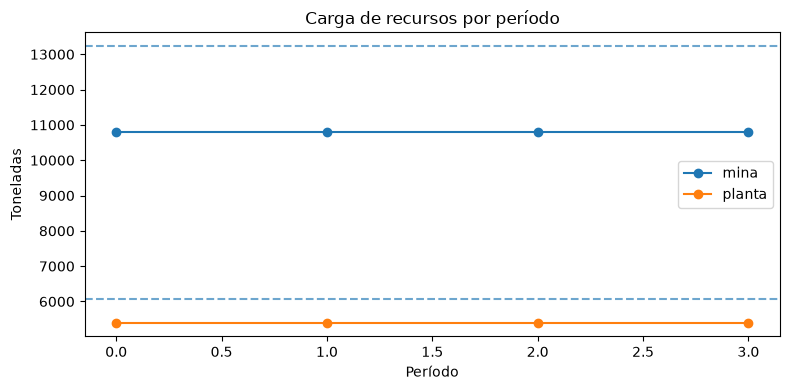

In [6]:
# Graficar el uso de recursos por período frente a sus límites.
fig,ax=plt.subplots(figsize=(8,4))
for r,label in enumerate(('mina','planta')):
    ax.plot(range(instance.cpit.n_periods),expected.per_period_resource[r],marker='o',label=label)
    ax.axhline(instance.cpit.limit[r,0],linestyle='--',alpha=.65)
ax.set(
    title='Carga de recursos por período', xlabel='Período', ylabel='Toneladas',
)
ax.legend()
fig.tight_layout()
plt.show()

Las dos curvas y sus líneas discontinuas muestran el consumo y capacidad por recurso en toneladas. Identifique el período de mayor utilización; no infiera precedencias ni valor descontado. El control del paquete comprueba la matriz completa y sigue siendo la autoridad de factibilidad.

Paso 4. Grafique las brechas calculadas contra la misma cota superior.

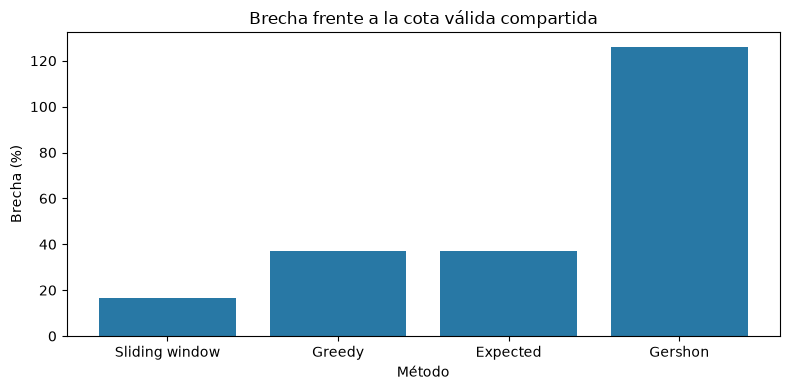

In [7]:
# Graficar brechas comparables: una barra menor indica mayor valor factible en este caso.
fig,ax=plt.subplots(figsize=(8,4))
ax.bar([row['metodo'] for row in comparison], [row['brecha %'] for row in comparison], color='#2878a5')
ax.set(title='Brecha frente a la cota válida compartida',xlabel='Método',ylabel='Brecha (%)')
fig.tight_layout()
plt.show()

Esta figura ordena distancias medidas para esta ejecución; una barra menor indica que el plan quedó más cerca de la cota común, no que sea universalmente mejor. Sliding window usó un nodo límite determinista, lo que condiciona su búsqueda. Ni la distancia ni la terminación del solver demuestran optimalidad global.

In [8]:
# Mejorar Expected localmente y repetir controles independientes del paquete.
improved=ob.improve_schedule(instance.cpit,instance.precedence,expected)
controls=ob.run_controls(instance.cpit,instance.precedence,improved)
print('VPN mejorado:',round(improved.npv,2),'antes:',round(expected.npv,2))
print(controls.__dict__)
best=comparison[0]
print('mejor método:',best['metodo'],'VPN:',round(best['VPN'],2),'brecha %:',round(best['brecha %'],3))

VPN mejorado: 179078.25 antes: 179078.25
{'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0}
mejor método: Sliding window VPN: 237344.67 brecha %: 16.629


La mejora local cambia una solución factible; vuelve a ejecutar los controles de cota y orden antes de interpretar su valor.

In [9]:
# Volver a comprobar la solución mejorada con controles independientes.
improved_controls = ob.run_controls(instance.cpit, instance.precedence, improved)
print('controles de la solución mejorada aprobados:', improved_controls.all_pass)


controles de la solución mejorada aprobados: True


## Resultados

**Respuesta:** Sliding window obtuvo el mayor VPN medido: 237344.67, con brecha 16.629% frente a la cota compartida 284685.82. Las figuras muestran carga y brechas en esta instancia. El límite de nodos forma parte del método; no se demuestra optimalidad global.

## Resumen

La relajación certifica un techo; los métodos generan planes factibles y la mejora local puede cerrar parte de la brecha. Esta brecha combina holgura de relajación y pérdida heurística. El experimento pequeño enseña el mecanismo, mientras los dossiers y trazas de casos preparados contienen la evidencia para comparar resultados de producto.

## Referencias

- Chicoisne et al. (2012), cierres máximos paramétricos: https://doi.org/10.1287/opre.1120.1050
- Rivera Letelier et al. (2020), métodos de planificación evaluados: https://doi.org/10.1287/opre.2019.1965
- Registro agregado Newman1 de MineLib: https://minelib.org/v1/Results.xhtml
- Dossier PhaseFlow: docs/methodologies/02_the-bound.md
- Caso PhaseFlow: docs/cases/04_twin-porphyry-s.md
- Repositorio PhaseFlow y generador de gemelos sintéticos: https://github.com/fsantibanezleal/CAOS_PhaseFlow